# Dengue High-Risk Month Prediction for Sri Lankan Districts
### ML Lecture 7 — Class Activity: Random Forest vs XGBoost (+ Stacking & Soft Voting)

**Problem.** Dengue is one of Sri Lanka's biggest public-health burdens. Regional health offices (RDHS / MOH) have to decide each month where to send fogging teams, run larval-source clean-ups and prepare hospital beds. This notebook predicts whether a district is about to have a **high-dengue month**.

**Task type:** binary classification
* `1 = High risk`: this month's cases exceed the district's own 75th percentile (computed from 2010–2018 data only)
* `0 = Normal`

**Inputs (what a health officer knows at the start of the month):** district, calendar month, cases in the previous 3 months, and cases in the same month last year.

**Dataset.** Monthly reported dengue cases for 26 Sri Lankan districts / RDHS areas, January 2010 – December 2020 (3,432 rows). Source: Epidemiology Unit, Ministry of Health figures as published on Kaggle and redistributed in the `denguedatasets` PyPI package.

In [1]:
import sys, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

from features import build_features, DISTRICT_FIX, NUMERIC_FEATURES, CATEGORICAL_FEATURES, RAW_INPUTS

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
RANDOM_STATE = 42

## 1. Load and understand the data

In [2]:
raw = pd.read_csv("data/sri_lanka_dengue_monthly_2010_2020.csv", parse_dates=["date"])
print(raw.shape)
raw.head()

(3432, 3)


,date,district,cases
0,2010-01-01,Colombo,584
1,2010-02-01,Colombo,606
2,2010-03-01,Colombo,294
3,2010-04-01,Colombo,224
4,2010-05-01,Colombo,296


In [3]:
print("Unique district names in the raw file:\n", sorted(raw["district"].unique()))

Unique district names in the raw file:
 ['Ampara', 'Anuradapura', 'Badulla', 'Battocolo', 'Colombo', 'Galle', 'Gampaha', 'Hambantota', 'Jaffna', 'Kalminai', 'Kalutara', 'Kandy', 'Kegalla', 'Killinochchi', 'Kurunegala', 'Mannar', 'Matale', 'Matara', 'Monaragala', 'Mulative', 'N eliya', 'Polonnaruwa', 'Puttalama', 'Rathnapura', 'Trincomalee', 'Vauniya']


**Domain-knowledge cleaning.** The raw file uses informal spellings (`Battocolo`, `N eliya`, `Mulative` …). These are mapped to the official names. There are **26** areas, not 25 districts, because the Ministry reports **Kalmunai** as a separate RDHS area carved out of Ampara.

In [4]:
df = raw.copy()
df["district"] = df["district"].replace(DISTRICT_FIX)
df = df.sort_values(["district", "date"]).reset_index(drop=True)
print(sorted(df["district"].unique()))
print("Rows per district:", df.groupby("district").size().unique())

['Ampara', 'Anuradhapura', 'Badulla', 'Batticaloa', 'Colombo', 'Galle', 'Gampaha', 'Hambantota', 'Jaffna', 'Kalmunai', 'Kalutara', 'Kandy', 'Kegalle', 'Kilinochchi', 'Kurunegala', 'Mannar', 'Matale', 'Matara', 'Monaragala', 'Mullaitivu', 'Nuwara Eliya', 'Polonnaruwa', 'Puttalam', 'Ratnapura', 'Trincomalee', 'Vavuniya']
Rows per district: [132]


### 1.1 Null-value detection and basic statistics

In [5]:
print("Missing values per column:\n", df.isna().sum())
print("\nDuplicated (district, date) rows:", df.duplicated(["district", "date"]).sum())
print("Negative case counts:", (df["cases"] < 0).sum())
df["cases"].describe()

Missing values per column:
 date        0
district    0
cases       0
dtype: int64

Duplicated (district, date) rows: 0
Negative case counts: 0


count    3432.000000
mean      188.107517
std       429.603007
min         0.000000
25%        21.000000
50%        58.000000
75%       170.000000
max      9039.000000
Name: cases, dtype: float64

The raw file has **no nulls, no duplicates and no negative counts**. Case counts are **heavily right-skewed**: the median is 58 but the maximum is 9,039 (Colombo during the 2017 epidemic). That skew is why a `log1p` transformation is applied to every count feature.

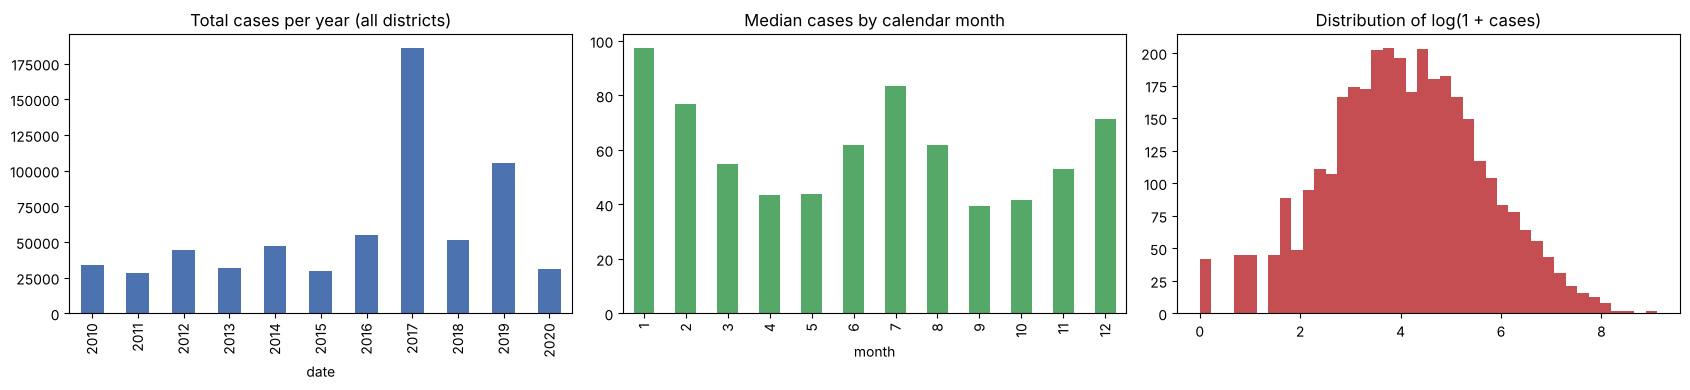

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
yearly = df.groupby(df["date"].dt.year)["cases"].sum()
yearly.plot(kind="bar", ax=axes[0], color="#4C72B0"); axes[0].set_title("Total cases per year (all districts)")
monthly = df.groupby(df["date"].dt.month)["cases"].median()
monthly.plot(kind="bar", ax=axes[1], color="#55A868"); axes[1].set_title("Median cases by calendar month"); axes[1].set_xlabel("month")
axes[2].hist(np.log1p(df["cases"]), bins=40, color="#C44E52"); axes[2].set_title("Distribution of log(1 + cases)")
plt.tight_layout(); plt.show()

In [7]:
top = df.groupby("district")["cases"].sum().sort_values(ascending=False)
print("Top 8 districts by total cases 2010–2020:\n", top.head(8))

Top 8 districts by total cases 2010–2020:
 district
Colombo       147726
Gampaha        97038
Kandy          45906
Kalutara       39960
Ratnapura      36300
Kurunegala     32971
Jaffna         31990
Galle          26075
Name: cases, dtype: int64


**What the EDA tells us (Sri Lankan context):**
* **2017 was an extreme epidemic year**, with about 186k cases, roughly 3–6× a normal year (DENV-2 serotype shift plus heavy south-west monsoon rains). **2019** was also a large outbreak year.
* **2020 collapses** to about 31k cases. COVID-19 lockdowns reduced movement and probably also reduced reporting and hospital visits. This creates a **distribution shift** between training and test years.
* The months chart has **two peaks**, mid-year (peaking in July, after the south-west / Yala monsoon) and December–January (after the north-east / Maha monsoon). That matches mosquito breeding after rain, so the monsoon flags and cyclic month features are well motivated.
* Western Province (Colombo, Gampaha, Kalutara) dominates totals because of urban density. A single nationwide "high" threshold would mark Colombo high every month and Mannar never. This is why the target is defined **per district**.

## 2. Feature engineering and target definition

Each row is a district-month. **Lag features** are created from the district's own history:
* `lag1`, `lag2`, `lag3`: cases 1, 2 and 3 months earlier
* `lag12`: cases in the same month last year (seasonality)

Only past values are used, so nothing from the month being predicted leaks into the features.

In [8]:
g = df.groupby("district")["cases"]
for k in [1, 2, 3, 12]:
    df[f"lag{k}"] = g.shift(k)
df["month"] = df["date"].dt.month

print("Nulls created by lagging:\n", df[["lag1", "lag2", "lag3", "lag12"]].isna().sum())

Nulls created by lagging:
 lag1      26
lag2      52
lag3      78
lag12    312
dtype: int64


**Handling the nulls created by lagging:**
* The first 3 months of each district (Jan–Mar 2010) have no `lag1–3`. These rows are **dropped**, since we can't predict without any history.
* `lag12` is missing for the rest of 2010. These rows are **kept**, and `lag12` is filled by **median imputation** (`SimpleImputer`) inside the pipeline, so the imputation median is learned from training data only.

In [9]:
df = df.dropna(subset=["lag1", "lag2", "lag3"]).copy()
print("Remaining rows:", len(df), "| lag12 still missing:", df["lag12"].isna().sum())

Remaining rows: 3354 | lag12 still missing: 234


### 2.1 Target: per-district high-risk month
The threshold is each district's **75th percentile from 2010–2018 only**. Computing it on the test years would leak future information into the label.

In [10]:
TRAIN_LAST_YEAR = 2018
thresholds = df[df["date"].dt.year <= TRAIN_LAST_YEAR].groupby("district")["cases"].quantile(0.75)
df["high_risk"] = (df["cases"] > df["district"].map(thresholds)).astype(int)
print("High-risk thresholds (cases/month) for a few districts:\n", thresholds.loc[["Colombo", "Gampaha", "Jaffna", "Kandy", "Mannar"]].round(0))
print("\nShare of high-risk months by year:\n", df.groupby(df["date"].dt.year)["high_risk"].mean().round(2))

High-risk thresholds (cases/month) for a few districts:
 district
Colombo    1339.0
Gampaha     817.0
Jaffna      236.0
Kandy       301.0
Mannar       22.0
Name: cases, dtype: float64

Share of high-risk months by year:
 date
2010    0.16
2011    0.05
2012    0.16
2013    0.05
2014    0.19
2015    0.07
2016    0.27
2017    0.92
2018    0.31
2019    0.47
2020    0.16
Name: high_risk, dtype: float64


### 2.2 Keep one sample out for inference (Step 6)
**Colombo, December 2020** is removed before training. The model never sees it during training or testing, and it is used in Section 7 to show single-sample inference.

In [11]:
holdout = df[(df["district"] == "Colombo") & (df["date"] == "2020-12-01")]
data = df.drop(holdout.index)
holdout[["district", "date", "cases", "lag1", "lag2", "lag3", "lag12", "high_risk"]]

,district,date,cases,lag1,lag2,lag3,lag12,high_risk
659,Colombo,2020-12-01,92,59.0,151.0,192.0,3283.0,0


### 2.3 Time-based train / test split
This is time-series data, so a random split would let the model "see the future". It trains on **2010–2018** and tests on **2019–2020**. The test set is hard on purpose: it contains both a big outbreak (2019) and the COVID-19 collapse (2020).

In [12]:
train = data[data["date"].dt.year <= TRAIN_LAST_YEAR].sort_values("date")
test = data[data["date"].dt.year > TRAIN_LAST_YEAR].sort_values("date")
X_train, y_train = build_features(train), train["high_risk"]
X_test, y_test = build_features(test), test["high_risk"]
print("Train:", X_train.shape, "positive rate %.2f" % y_train.mean())
print("Test: ", X_test.shape, "positive rate %.2f" % y_test.mean())
X_train.head()

Train: (2730, 11) positive rate 0.25
Test:  (623, 11) positive rate 0.31


,district,log_lag1,log_lag2,log_lag3,log_lag12,log_roll3,growth_1m,month_sin,month_cos,is_sw_monsoon,is_ne_monsoon
3,Ampara,3.258097,2.639057,2.564949,NaN,2.871680,0.619039,0.866025,-0.5,0,0
267,Badulla,3.912023,4.234107,4.276666,NaN,4.153661,-0.322083,0.866025,-0.5,0,0
1719,Kilinochchi,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.866025,-0.5,0,0
1587,Kegalle,4.343805,4.919981,4.510860,NaN,4.621699,-0.576176,0.866025,-0.5,0,0
2907,Puttalam,4.465908,5.247024,5.342334,NaN,5.087596,-0.781116,0.866025,-0.5,0,0


**Engineered features** (see `features.py`, which the web app shares):

| Feature | Why |
|---|---|
| `log_lag1..3`, `log_lag12` | `log1p` transformation tames the heavy right skew of case counts |
| `log_roll3` | 3-month average level, which smooths reporting noise |
| `growth_1m` | log(lag1) − log(lag2). Is the epidemic curve rising? |
| `month_sin`, `month_cos` | cyclic encoding, so December and January sit next to each other |
| `is_sw_monsoon` (May–Sep), `is_ne_monsoon` (Dec–Feb) | Sri Lankan monsoon seasons that drive breeding |
| `district` | one-hot encoded, since each district has its own baseline |

### 2.4 Preprocessing pipeline
* **Categorical:** `OneHotEncoder(handle_unknown="ignore")`
* **Numeric:** `SimpleImputer(median)` → `StandardScaler`

Trees don't need scaling, but the **logistic-regression meta-learner** in the stacking model does. Keeping a single shared pipeline also means the `.pkl` file contains every preprocessing step.

In [13]:
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUMERIC_FEATURES),
])

## 3. Parameter engineering (no default parameters)

The dataset is **small** (about 2,700 training rows, 35 features after one-hot encoding), **noisy** (reporting delays) and **imbalanced** (about 25% positives). The parameters were designed around those facts first, then checked with a small grid search using **TimeSeriesSplit** (always validating on later years than the model trained on).

In [14]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
print(f"neg={neg}, pos={pos}, scale_pos_weight={scale_pos_weight:.2f}")

tscv = TimeSeriesSplit(n_splits=4)

rf_grid = GridSearchCV(
    Pipeline([("pre", preprocess), ("model", RandomForestClassifier(
        n_estimators=300, max_features="sqrt", class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))]),
    {"model__max_depth": [6, 10, 14], "model__min_samples_leaf": [2, 5, 10]},
    cv=tscv, scoring="f1", n_jobs=-1)
rf_grid.fit(X_train, y_train)

xgb_grid = GridSearchCV(
    Pipeline([("pre", preprocess), ("model", XGBClassifier(
        n_estimators=300, subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
        scale_pos_weight=scale_pos_weight, eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE))]),
    {"model__max_depth": [3, 4, 6], "model__learning_rate": [0.03, 0.05, 0.1]},
    cv=tscv, scoring="f1", n_jobs=-1)
xgb_grid.fit(X_train, y_train)

def grid_table(gs):
    t = pd.DataFrame(gs.cv_results_["params"])
    t.columns = [c.replace("model__", "") for c in t.columns]
    t["mean_cv_f1"] = gs.cv_results_["mean_test_score"].round(3)
    return t.sort_values("mean_cv_f1", ascending=False)

print("Random Forest grid:"); print(grid_table(rf_grid).to_string(index=False))
print("\nXGBoost grid:"); print(grid_table(xgb_grid).to_string(index=False))

neg=2060, pos=670, scale_pos_weight=3.07


Random Forest grid:
 max_depth  min_samples_leaf  mean_cv_f1
         6                 5       0.532
         6                10       0.528
        10                10       0.526
        14                10       0.525
         6                 2       0.516
        10                 5       0.501
        14                 5       0.495
        10                 2       0.475
        14                 2       0.464

XGBoost grid:
 learning_rate  max_depth  mean_cv_f1
          0.10          3       0.442
          0.05          4       0.431
          0.10          4       0.430
          0.03          3       0.428
          0.03          4       0.427
          0.05          3       0.422
          0.03          6       0.413
          0.05          6       0.398
          0.10          6       0.383


**Final hyperparameters and reasoning**

**Random Forest**
| Parameter | Value | Reasoning |
|---|---|---|
| `n_estimators` | 500 | More trees reduce variance. Scores stabilise well before 500, and training stays under a few seconds. |
| `max_depth` | 6 | The grid search preferred shallow trees. With about 2.7k noisy rows, deep trees memorise individual outbreaks. |
| `min_samples_leaf` | 10 | Each leaf must represent at least 10 district-months, a strong guard against overfitting to reporting noise. CV F1 was essentially tied with 5 (0.528 vs 0.532), so the more conservative value was chosen. Small leaves (2) were clearly worse. |
| `max_features` | `"sqrt"` | Decorrelates trees. Otherwise `lag1` would dominate every split. |
| `class_weight` | `"balanced"` | About 25% positives. Missing an outbreak costs more than a false alarm. |
| `bootstrap` | True | Classic bagging. |

**XGBoost**
| Parameter | Value | Reasoning |
|---|---|---|
| `n_estimators` | 300 | Paired with a small learning rate. |
| `learning_rate` | 0.05 | Small steps plus 300 trees generalise better on small data. 0.1 scored slightly higher in CV (about 0.02 F1), but that difference is within fold-to-fold noise, so the slower, safer rate was kept. |
| `max_depth` | 3 | Boosting builds many shallow "weak learners". Depth 6 was clearly worse in CV. |
| `subsample`, `colsample_bytree` | 0.8 | Row and column sampling adds randomness and reduces overfitting. |
| `min_child_weight` | 3 | Stops splits on very few samples. |
| `gamma` | 0.1 | A split must improve the loss by at least this much (pruning). |
| `reg_lambda` | 2.0 | Stronger L2 regularisation on leaf weights than the default. |
| `scale_pos_weight` | neg/pos ≈ 3.1 | Handles class imbalance. |

Note that the CV folds include the 2017 epidemic, when about 92% of months were "high", so absolute CV F1 values are lower than the final test scores. The grid is used to **compare settings**, not to report performance.

In [15]:
rf = RandomForestClassifier(
    n_estimators=500, max_depth=6, min_samples_leaf=10, max_features="sqrt",
    class_weight="balanced", bootstrap=True, n_jobs=-1, random_state=RANDOM_STATE)

xgb = XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
    min_child_weight=3, gamma=0.1, reg_lambda=2.0, scale_pos_weight=scale_pos_weight,
    eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE)

## 4. Train the models
Four models are trained, all sharing the same preprocessing:
1. **Random Forest** (bagging)
2. **XGBoost** (boosting)
3. **Soft Voting** RF + XGBoost, as in the lecturer's notebook (average of predicted probabilities)
4. **Stacking** (optional extension): RF + XGBoost as base learners, with a **logistic regression** meta-learner that learns how much to trust each one

In [16]:
models = {
    "Random Forest": Pipeline([("pre", preprocess), ("model", rf)]),
    "XGBoost": Pipeline([("pre", preprocess), ("model", xgb)]),
    "Soft Voting (RF+XGB)": Pipeline([("pre", preprocess), ("model", VotingClassifier(
        [("rf", rf), ("xgb", xgb)], voting="soft", weights=[1, 1]))]),
    "Stacking (RF+XGB → LR)": Pipeline([("pre", preprocess), ("model", StackingClassifier(
        [("rf", rf), ("xgb", xgb)],
        final_estimator=LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000),
        stack_method="predict_proba", cv=5))]),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print("trained:", name)

trained: Random Forest
trained: XGBoost


trained: Soft Voting (RF+XGB)


trained: Stacking (RF+XGB → LR)


## 5. Evaluate and compare

A **naive persistence baseline** is included: "predict high if last month was already above the threshold". This is the rule a health officer would use without any ML. A model is only useful if it beats this.

In [17]:
def scores(y_true, y_pred, y_prob=None):
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred), "F1": f1_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan}

rows, probs = {}, {}
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]
    probs[name] = p
    rows[name] = scores(y_test, (p >= 0.5).astype(int), p)
baseline_pred = (test["lag1"] > test["district"].map(thresholds)).astype(int)
rows["Baseline: last month high"] = scores(y_test, baseline_pred)

results = pd.DataFrame(rows).T.round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest,0.799,0.650,0.779,0.709,0.878
XGBoost,0.857,0.737,0.846,0.788,0.925
Soft Voting (RF+XGB),0.846,0.726,0.815,0.768,0.914
Stacking (RF+XGB → LR),0.839,0.697,0.862,0.771,0.928
Baseline: last month high,0.865,0.773,0.805,0.789,NaN


In [18]:
# Train vs test F1, to check for overfitting
fit_check = pd.DataFrame({
    name: {"Train F1": f1_score(y_train, m.predict(X_train)), "Test F1": f1_score(y_test, m.predict(X_test))}
    for name, m in models.items()}).T.round(3)
fit_check["Gap"] = (fit_check["Train F1"] - fit_check["Test F1"]).round(3)
fit_check

,Train F1,Test F1,Gap
Random Forest,0.640,0.709,-0.069
XGBoost,0.775,0.788,-0.013
Soft Voting (RF+XGB),0.734,0.768,-0.034
Stacking (RF+XGB → LR),0.756,0.771,-0.015


In [19]:
# Results by test year: outbreak year (2019) vs COVID year (2020)
by_year = {}
for name, m in models.items():
    for yr in [2019, 2020]:
        mask = (test["date"].dt.year == yr).values
        by_year[(name, yr)] = f1_score(y_test[mask], (probs[name][mask] >= 0.5).astype(int))
for yr in [2019, 2020]:
    mask = (test["date"].dt.year == yr).values
    by_year[("Baseline: last month high", yr)] = f1_score(y_test[mask], baseline_pred[mask])
pd.Series(by_year).unstack().round(3).rename(columns=lambda c: f"F1 {c}")

,F1 2019,F1 2020
Baseline: last month high,0.812,0.738
Random Forest,0.736,0.646
Soft Voting (RF+XGB),0.787,0.724
Stacking (RF+XGB → LR),0.786,0.734
XGBoost,0.805,0.746


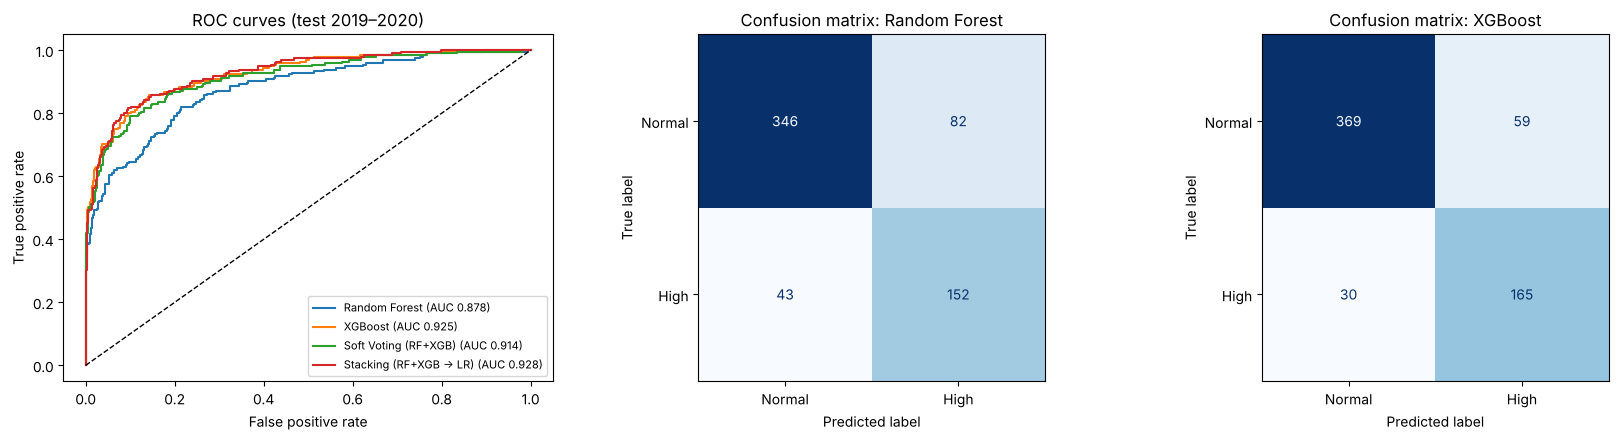

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC curves (test 2019–2020)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend(fontsize=8)
for ax, name in zip(axes[1:], ["Random Forest", "XGBoost"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (probs[name] >= 0.5).astype(int)),
                           display_labels=["Normal", "High"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Confusion matrix: {name}")
plt.tight_layout(); plt.show()

### 5.1 What drives the predictions?
Permutation importance on the **test set**: shuffle one raw feature and measure how much the ROC-AUC drops. This works the same way for both models and is less biased than built-in tree importances.

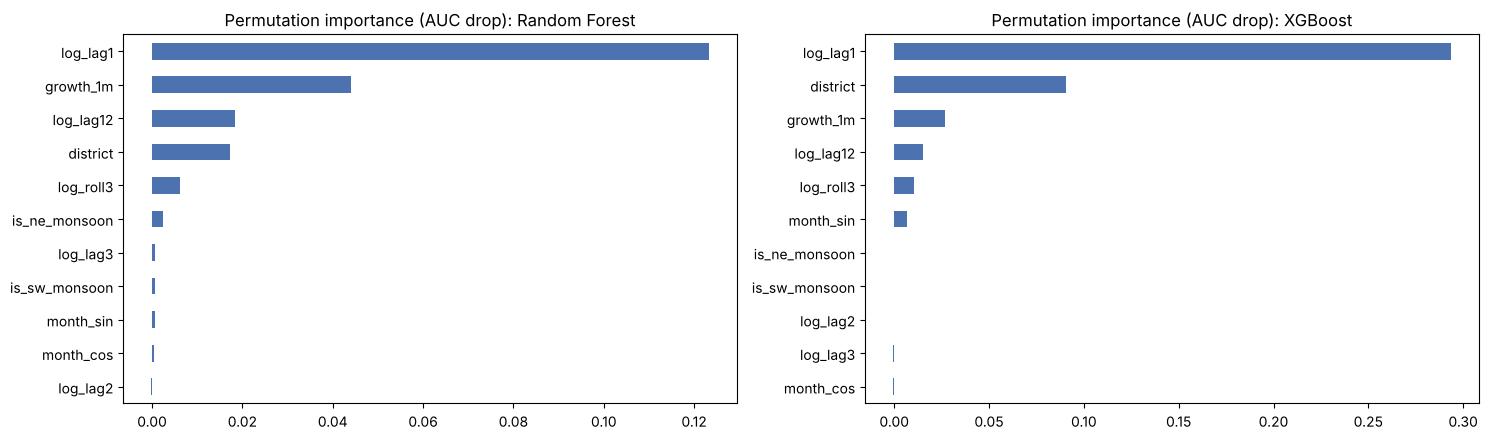

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    pi = permutation_importance(models[name], X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE)
    imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
    imp.plot(kind="barh", ax=ax, color="#4C72B0"); ax.set_title(f"Permutation importance (AUC drop): {name}")
plt.tight_layout(); plt.show()

## 5.2 Interpretation of the results

**Headline numbers (test set: 623 district-months in 2019–2020):**

| | Accuracy | F1 | ROC-AUC |
|---|---|---|---|
| Random Forest | 0.80 | 0.71 | 0.88 |
| **XGBoost** | **0.86** | **0.79** | 0.93 |
| Soft Voting | 0.85 | 0.77 | 0.91 |
| Stacking | 0.84 | 0.77 | **0.93** (highest recall, 0.86) |
| Baseline "last month high" | 0.87 | 0.79 | n/a |

**1. XGBoost is the best single model.** It beats Random Forest on every metric (F1 0.79 vs 0.71, AUC 0.93 vs 0.88). Boosting builds trees one after another, each fixing the previous trees' mistakes, so it captures the sharp threshold behaviour in the data ("once last month passes about X cases, risk jumps"). The RF averages many independent shallow trees, which smooths those sharp edges.

**2. Last month's cases dominate.** Permutation importance shows `log_lag1` is by far the most important feature for both models, followed by **momentum** (`growth_1m`) and the **district** baseline. Epidemiologically this makes sense. Dengue spreads person → mosquito → person in about 2–3-week cycles, so this month's transmission comes from last month's infections. Calendar and monsoon features add little *once lag1 is known*, because last month's cases already "contain" the effect of the rain.

**3. An honest finding: ML only matches a simple rule on F1.** The rule "high if last month was high" has F1 0.79, the same as XGBoost. So for a plain yes/no decision, the models do not add much. Where they **do** add value:
* They give a **probability** (AUC 0.93), not just yes/no, so districts can be **ranked** by risk and limited fogging teams sent to the top ones.
* **Stacking reaches recall 0.86** against the baseline's 0.80. It catches more of the real outbreaks, which matters because a missed outbreak costs far more than a false alarm.
* They can flag a **rising** district before it crosses the threshold (see the what-if example in Section 7). The baseline cannot, by definition.

**4. Robust to distribution shift.** 2020 cases collapsed because of COVID-19. XGBoost still scores F1 0.75 in 2020 (0.81 in 2019) because the features are **relative** (log counts, growth, per-district thresholds) rather than absolute.

**5. No overfitting.** Train F1 is *lower* than test F1 for every model. The models are well regularised, and the training years include the 2017 epidemic, which is unusually hard (92% of months were "high").

**6. Ensembles.** Soft voting (0.77) lands between RF and XGBoost, because averaging with the weaker RF pulls XGBoost down. Stacking learns the weights instead of using 50/50, so it recovers AUC 0.93 and gets the best recall. With only two base models that make similar errors, though, stacking adds limited diversity.

### Strengths and limitations

| | Strengths | Limitations |
|---|---|---|
| **Random Forest** | Very hard to overfit (bagging + `min_samples_leaf`). Few sensitive parameters. Trees are independent, so training parallelises. Stable importances. | Shallow averaged trees underfit sharp thresholds here (lowest F1/AUC). Uncalibrated probabilities. Large model file (500 trees). Cannot extrapolate above case counts seen in training. |
| **XGBoost** | Best accuracy, F1 and AUC. Built-in L1/L2 regularisation and `scale_pos_weight` for imbalance. Handles missing values natively. Fast, small model. | More hyperparameters, and sensitive to depth and learning rate (depth 6 was clearly worse). Sequential training. Easier to overfit if not regularised. Still a black box without SHAP or permutation tools. |
| **Stacking** | Highest recall and AUC. Learns how much to trust each base model. | More complex, slower, harder to explain. Small gain when base models are similar. Its internal CV uses K-fold, not time order. |

**Limitations of the study itself:** only case-count history is used. **Rainfall, temperature and humidity** from the Department of Meteorology, plus population density, would very likely improve early warning, especially at longer horizons (2–3 months ahead) where "last month" is less informative. The data also ends in 2020, and reporting delays at MOH level add noise.

## 6. Export the model (.pkl)
The **whole pipeline** (preprocessing and model) is saved, together with the per-district thresholds and metadata the web app needs. The web app uses **XGBoost**, the best single model on F1 and accuracy (see Section 5).

In [22]:
bundle = {
    "model": models["XGBoost"],
    "model_name": "XGBoost",
    "thresholds": thresholds.round(1).to_dict(),
    "districts": sorted(df["district"].unique()),
    "raw_inputs": RAW_INPUTS,
    "test_metrics": results.loc["XGBoost"].to_dict(),
    "train_years": "2010–2018",
}
with open("models/model.pkl", "wb") as f:
    pickle.dump(bundle, f)
# Also export the soft-voting ensemble, as in the lecturer's notebook
with open("models/ensemble_model.pkl", "wb") as f:
    pickle.dump(models["Soft Voting (RF+XGB)"], f)
print("saved models/model.pkl and models/ensemble_model.pkl")

saved models/model.pkl and models/ensemble_model.pkl


## 7. Inference on the held-out sample (Step 6)
The pickle file is reloaded from disk, the same way the web app does it, and used to predict **Colombo, December 2020**. This row was removed before training and testing.

In [23]:
with open("models/model.pkl", "rb") as f:
    loaded = pickle.load(f)

sample = holdout[RAW_INPUTS]
print("Input given to the model:")
print(sample.to_string(index=False))

prob_high = loaded["model"].predict_proba(build_features(sample))[0, 1]
pred = int(prob_high >= 0.5)
actual = int(holdout["high_risk"].iloc[0])
print(f"\nP(high-risk month) = {prob_high:.3f}")
print("Prediction :", "HIGH RISK" if pred else "Normal")
print("Actual     :", "HIGH RISK" if actual else "Normal",
      f"({int(holdout['cases'].iloc[0])} cases vs threshold {loaded['thresholds']['Colombo']:.0f})")

Input given to the model:
district  month  lag1  lag2  lag3  lag12
 Colombo     12  59.0 151.0 192.0 3283.0

P(high-risk month) = 0.072
Prediction : Normal
Actual     : Normal (92 cases vs threshold 1339)


In [24]:
# A "what-if" sample: the same month with numbers typical of a growing outbreak
what_if = pd.DataFrame([{"district": "Colombo", "month": 12, "lag1": 1400, "lag2": 900, "lag3": 600, "lag12": 3283}])
p = loaded["model"].predict_proba(build_features(what_if))[0, 1]
print(f"What-if (rising cases 600 → 900 → 1400): P(high) = {p:.3f} → {'HIGH RISK' if p >= .5 else 'Normal'}")

What-if (rising cases 600 → 900 → 1400): P(high) = 0.851 → HIGH RISK


## 8. Summary
* **Problem:** predict a high-dengue month for 26 Sri Lankan districts / RDHS areas from case history (classification).
* **Preprocessing:** name cleaning using domain knowledge, null detection, lag features, median imputation of `lag12`, `log1p` transformation, cyclic month encoding, monsoon flags, one-hot encoding, standard scaling, and a time-based split.
* **Models:** Random Forest and XGBoost with designed and CV-checked (non-default) parameters, plus Soft Voting and Stacking.
* **Result:** XGBoost is the best single model (F1 0.79, AUC 0.93). Stacking has the best recall. A naive persistence rule matches the F1, so the models' real value is in **risk ranking and early detection**.
* **Inference:** the held-out Colombo December 2020 sample was correctly predicted as *Normal* (P = 0.07; actual 92 cases vs a 1,339 threshold).
* **Deployment:** `models/model.pkl` is loaded by the Streamlit app in `app/app.py`.
* **Next step (final assignment):** add Department of Meteorology rainfall data and try LightGBM / CatBoost and an ARIMA + RF hybrid.